# FathomNet 2025 – compact ROI dataset, step by step

We turn the official FathomNet 2025 FGVC training set (8,981 full-resolution images) into a small
dataset of **224×224 crops** of the annotated organisms, and analyse its taxonomy.

| Step | What we do |
|---|---|
| 1 | Get the official repo + `dataset_train.json` |
| 2 | Look at the COCO structure |
| 3 | Integrity checks (what can go wrong *before* downloading) |
| 4 | One image by hand: download → crop → resize |
| 5 | Batch crops with the real pipeline + verification |
| 6 | Taxonomy from WoRMS (and its bug) |
| 7 | Taxonomic analysis |
| 8 | Full run + known issues |

All heavy lifting lives in `prepare_fathomnet2025.py`; this notebook calls its functions so you can see each step.
Set `N_IMAGES` below to control how much is downloaded (the full set is `None`, ~15 min, ~250 MB).

In [1]:
import io, json, sys, requests, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
sys.path.insert(0, str(Path.cwd()))
import prepare_fathomnet2025 as P

N_IMAGES = 40            # None = all 8,981 images
OUT = Path("fathomnet2025_compact_demo")

## 1. Official repo and source of truth
We never query the general FathomNet database; `dataset_train.json` *defines* the dataset. We pin the commit and hash so results are reproducible.

In [2]:
repo = P.get_official_repo("fgvc-comp-2025")
src = repo / "datasets" / "dataset_train.json"
print("commit:", P.git(repo, "rev-parse", "HEAD"))
print("sha256:", P.sha256_file(src))
data = json.loads(src.read_text())

Cloning https://github.com/fathomnet/fgvc-comp-2025 -> fgvc-comp-2025


Cloning into 'fgvc-comp-2025'...


commit: 297d7d26905f6dcc3bacd194cfb74dbbd5963b52
sha256: cb5c6017925c0bb64dd5ae659dcc4666151e848a3e52cef75b91a0b005ebe3be


## 2. COCO structure
Three tables: **images** (with `coco_url`), **annotations** (bbox = `[x, y, width, height]`), **categories** (79 concept names).

In [3]:
print({k: len(v) if isinstance(v, list) else v for k, v in data.items()})
display(pd.DataFrame(data["images"]).head(3))
display(pd.DataFrame(data["annotations"]).head(3))
display(pd.DataFrame(data["categories"]).head(3))

{'info': {'year': 2025, 'version': '0', 'description': 'Generated by FathomNet', 'contributor': 'FathomNet', 'url': 'https://database.fathomnet.org', 'date_created': '2025/01/08'}, 'images': 8981, 'licenses': 1, 'annotations': 23699, 'categories': 79}


,id,width,height,file_name,license,flickr_url,coco_url,date_captured
0,1,720,368,67cda248-6d28-4801-9c4e-e4525189ea38.png,0,https://database.fathomnet.org/static/m3/frame...,https://database.fathomnet.org/static/m3/frame...,2008-12-19 19:46:56
1,2,1920,1080,d9b399f3-8628-4138-a339-f4520be751c5.png,0,https://database.fathomnet.org/static/m3/frame...,https://database.fathomnet.org/static/m3/frame...,2019-05-30 16:41:04
2,3,1920,1080,3289c3e1-40f2-4512-992f-3fa406b50a86.png,0,https://database.fathomnet.org/static/m3/frame...,https://database.fathomnet.org/static/m3/frame...,2014-06-05 20:04:19


,id,image_id,category_id,segmentation,area,bbox,iscrowd
0,1,1,71,[],943.0,"[491.0, 254.0, 23.0, 41.0]",0
1,2,2,8,[],71577.0,"[701.0, 505.0, 241.0, 297.0]",0
2,3,3,67,[],533148.0,"[458.0, 332.0, 924.0, 577.0]",0


,id,name,supercategory
0,1,Abyssocucumis abyssorum,
1,2,Acanthascinae,
2,3,Acanthoptilum,


## 3. Integrity checks before downloading
The task description says *79 × 300 = 23,700* annotations. **Do not assume it – check.**

In [4]:
report, images, cats = P.check_json(data)
pd.Series({k: v for k, v in report.items() if k != "categories_not_exactly_300"}).to_frame("value")

,value
n_images,8981
n_categories,79
n_annotations,23699
expected_annotations_if_79x300,23700
unique_annotation_ids,True
annotations_with_invalid_image,0
annotations_with_invalid_category,0
bboxes_extending_outside_image_(will_be_clipped),16
bboxes_empty_after_clipping,1
categories_without_annotations,[]


In [5]:
print("Categories that are not exactly 300:", report["categories_not_exactly_300"])
ann = pd.DataFrame(data["annotations"])
ann[["x", "y", "w", "h"]] = pd.DataFrame(ann.bbox.tolist(), index=ann.index)
ann["W"] = ann.image_id.map(lambda i: images[i]["width"]); ann["H"] = ann.image_id.map(lambda i: images[i]["height"])
outside = ann[(ann.x < 0) | (ann.y < 0) | (ann.x + ann.w > ann.W) | (ann.y + ann.h > ann.H)]
print(f"{len(outside)} boxes leave the image (mostly by 1-10 px -> we clip them):")
display(outside[["id", "image_id", "bbox", "W", "H"]])

Categories that are not exactly 300: {'Elpidia': 299}
16 boxes leave the image (mostly by 1-10 px -> we clip them):


,id,image_id,bbox,W,H
1670,1671,413,"[1281.0, 998.0, 143.0, 83.0]",1920,1080
3590,3591,922,"[68.0, -1.0, 1087.0, 892.0]",1600,900
5867,5868,1595,"[1546.0, 615.0, 375.0, 440.0]",1920,1080
6505,6506,1801,"[0.0, 0.0, 815.0, 1105.0]",1920,1080
7150,7151,2001,"[47.0, 43.0, 1875.0, 1034.0]",1920,1080
7688,7689,2199,"[1499.0, 733.0, 327.0, 352.0]",1920,1080
8277,8278,2421,"[274.0, 576.0, 539.0, 516.0]",1920,1080
8524,8525,2491,"[-9.0, 3.0, 1929.0, 1076.0]",1920,1080
11367,11368,3488,"[639.0, 508.0, 1107.0, 578.0]",1920,1080
11436,11437,3523,"[1857.0, 416.0, 64.0, 86.0]",1920,1080


In [6]:
# duplicated boxes on the same image (possible double labelling)
k = ["image_id", "x", "y", "w", "h"]
dups = ann[ann.duplicated(k, keep=False)]
g = dups.groupby(k).category_id.nunique()
print(f"{len(g)} duplicated boxes; {int((g > 1).sum())} of them carry CONFLICTING labels")
# box size distribution -> many objects are tiny, upscaling to 224 blurs them
print(ann[["w", "h"]].describe().round(0))
print("boxes with a side < 32 px:", int(((ann.w < 32) | (ann.h < 32)).sum()))

30 duplicated boxes; 3 of them carry CONFLICTING labels
             w        h
count  23699.0  23699.0
mean     124.0    115.0
std      188.0    153.0
min        5.0      4.0
25%       43.0     40.0
50%       73.0     68.0
75%      126.0    120.0
max     1929.0   1105.0
boxes with a side < 32 px: 4589


## 4. One image by hand
Download into memory → crop `(x, y, x+w, y+h)` → RGB → resize to 224×224 (bicubic). The original is never written to disk.

source: (1920, 1080) RGB | bbox: [701.0, 505.0, 241.0, 297.0] | crop: (241, 297) ->  (224, 224) | category: Apostichopus leukothele


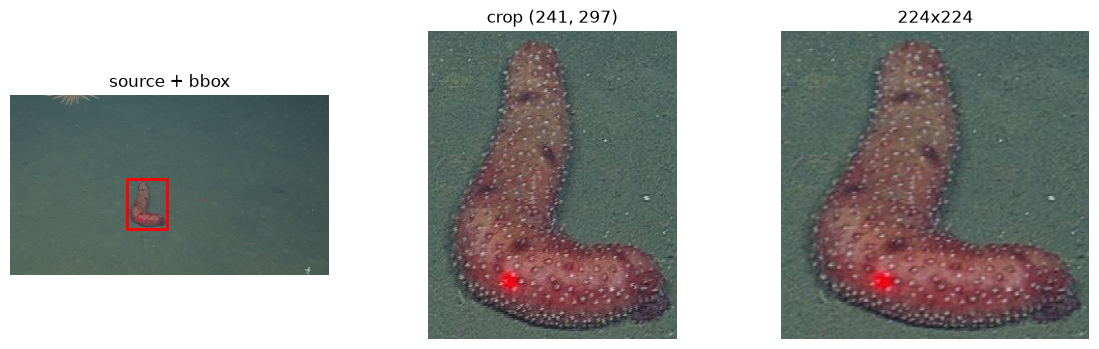

In [7]:
a = data["annotations"][1]
im = images[a["image_id"]]
img = P.fetch_image(im["coco_url"])
x, y, w, h = a["bbox"]
crop = img.crop((x, y, x + w, y + h)).convert("RGB")
small = crop.resize((224, 224), Image.BICUBIC)
print("source:", img.size, img.mode, "| bbox:", a["bbox"], "| crop:", crop.size, "-> ", small.size,
      "| category:", cats[a["category_id"]]["name"])
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(img); ax[0].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="red", lw=2)); ax[0].set_title("source + bbox")
ax[1].imshow(crop); ax[1].set_title(f"crop {crop.size}")
ax[2].imshow(small); ax[2].set_title("224x224")
for s in ax: s.axis("off")
plt.show()

## 5. The real pipeline on a subset
`build_crops` downloads each image **once**, cuts all its ROIs (`<image_id>_<annotation_id>.jpg`, so two ROIs of one image never collide) and discards the image. `verify_crops` re-opens every file.

In [8]:
keep = {i["id"] for i in data["images"][:N_IMAGES]} if N_IMAGES else set(images)
anns = [a for a in data["annotations"] if a["image_id"] in keep]
rows, failures = P.build_crops(images, anns, cats, OUT, workers=8, resample=P.INTERPOLATIONS["bicubic"], force=False)
for r in rows: r["_abs"] = OUT / r["crop_path"]
bad = P.verify_crops(rows)
print(f"{len(rows)} crops, {len(failures)} failures, {len(bad)} failed verification")
df = pd.DataFrame(rows).drop(columns="_abs"); df.head()

  images 40/40  crops 142  failed 0  6s


142 crops, 0 failures, 0 failed verification


,annotation_id,image_id,category_id,crop_path,bbox_x,bbox_y,bbox_width,bbox_height,source_url,bbox_clipped,image_width,image_height,concept_name
0,1,1,71,images/1_1.jpg,491.0,254.0,23.0,41.0,https://database.fathomnet.org/static/m3/frame...,0,720,368,Sebastolobus
1,2,2,8,images/2_2.jpg,701.0,505.0,241.0,297.0,https://database.fathomnet.org/static/m3/frame...,0,1920,1080,Apostichopus leukothele
2,3,3,67,images/3_3.jpg,458.0,332.0,924.0,577.0,https://database.fathomnet.org/static/m3/frame...,0,1920,1080,Scotoplanes
3,4,4,37,images/4_4.jpg,1155.0,71.0,659.0,454.0,https://database.fathomnet.org/static/m3/frame...,0,1920,1080,Keratoisis
4,5,4,37,images/4_5.jpg,66.0,6.0,975.0,534.0,https://database.fathomnet.org/static/m3/frame...,0,1920,1080,Keratoisis


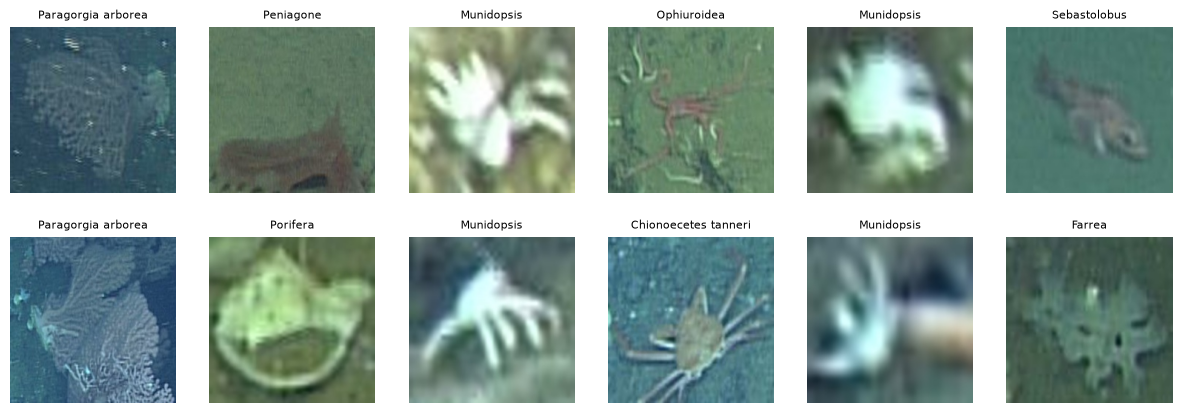

In [9]:
fig, axs = plt.subplots(2, 6, figsize=(15, 5))
for ax, (_, r) in zip(axs.ravel(), df.sample(12, random_state=0).iterrows()):
    ax.imshow(Image.open(OUT / r.crop_path)); ax.set_title(r.concept_name[:22], fontsize=8); ax.axis("off")
plt.show()

## 6. Taxonomy from WoRMS
`fathomnet.api.worms.get_ancestors` returns a nested tree root → taxon. **Bug to know:** for some leaf taxa the `rank` is an empty string – we infer it from the name (`label_rank_inferred=1`).

In [10]:
from fathomnet.api import worms
n = worms.get_ancestors("Terebellidae")
while n:
    print(repr(n.rank).ljust(16), n.name); n = n.children[0] if n.children else None

''               object
'Superdomain'    Biota
'Kingdom'        Animalia
'Phylum'         Annelida
'Class'          Polychaeta
'Subclass'       Sedentaria
'Infraclass'     Canalipalpata
'Order'          Terebellida
'Suborder'       Terebelliformia
''               Terebellidae


In [11]:
OUT.mkdir(exist_ok=True)
tax_rows, tax_err = P.build_taxonomy([c["name"] for c in cats.values()], OUT / "taxonomy_cache.json")   # cached: 1 query per taxon
tax = pd.DataFrame(tax_rows); print("lookup errors:", tax_err)
display(tax[tax.label_rank_inferred == 1]); tax.head(8)

lookup errors: {}


,concept_name,label_rank,label_rank_inferred,kingdom,phylum,class,order,family,genus,species
73,Strongylocentrotus fragilis,species,1,Animalia,Echinodermata,Echinoidea,Camarodonta,Strongylocentrotidae,Strongylocentrotus,Strongylocentrotus fragilis
74,Terebellidae,family,1,Animalia,Annelida,Polychaeta,Terebellida,Terebellidae,,


,concept_name,label_rank,label_rank_inferred,kingdom,phylum,class,order,family,genus,species
0,Abyssocucumis abyssorum,species,0,Animalia,Echinodermata,Holothuroidea,Dendrochirotida,Cucumariidae,Abyssocucumis,Abyssocucumis abyssorum
1,Acanthascinae,subfamily,0,Animalia,Porifera,Hexactinellida,Lyssacinosida,Rossellidae,,
2,Acanthoptilum,genus,0,Animalia,Cnidaria,Octocorallia,Scleralcyonacea,Virgulariidae,Acanthoptilum,
3,Actinernus,genus,0,Animalia,Cnidaria,Hexacorallia,Actiniaria,Actinernidae,Actinernus,
4,Actiniaria,order,0,Animalia,Cnidaria,Hexacorallia,Actiniaria,,,
5,Actinopterygii,gigaclass,0,Animalia,Chordata,,,,,
6,Amphipoda,order,0,Animalia,Arthropoda,Malacostraca,Amphipoda,,,
7,Apostichopus leukothele,species,0,Animalia,Echinodermata,Holothuroidea,Synallactida,Stichopodidae,Apostichopus,Apostichopus leukothele


## 7. Taxonomic analysis
Species-level labels are only ~40% of the classes; the others are genus/family/order/class/phylum labels – hierarchical structure is real and mixed-rank.

In [12]:
s = P.analyse(report, cats, tax_rows, tax_err, rows, len(failures), len(data["annotations"]), failures)
print(P.format_report(s, P.human(P.dir_size(OUT))))

FathomNet 2025 compact dataset

Categories: 79
Annotations in official JSON: 23699 (nominal 79 x 300 = 23700)
Crops successfully generated: 142
Failed: 0

Label ranks:
  species: 33
  genus: 21
  family: 8
  order: 6
  class: 6
  phylum: 1
  other/unknown: 4

Unique taxonomic groups:
  phyla: 7
  classes: 17
  orders: 32
  families: 49
  genera: 49
  species: 33

Disk usage: 1.6 MB

Top 10 phylum groups by ROI samples:
      46  Echinodermata
      34  Cnidaria
      32  Arthropoda
      21  Porifera
       6  Chordata
       2  Annelida
       1  Mollusca

Top 10 class groups by ROI samples:
      32  Malacostraca
      28  Octocorallia
      23  Holothuroidea
      17  (label above this rank)
      10  Crinoidea
       6  Asteroidea
       6  Hexacorallia
       5  Teleostei
       5  Hexactinellida
       5  Ophiuroidea

Top 10 order groups by ROI samples:
      39  (label above this rank)
      30  Decapoda
      23  Scleralcyonacea
      13  Elasipodida
       5  Perciformes
     

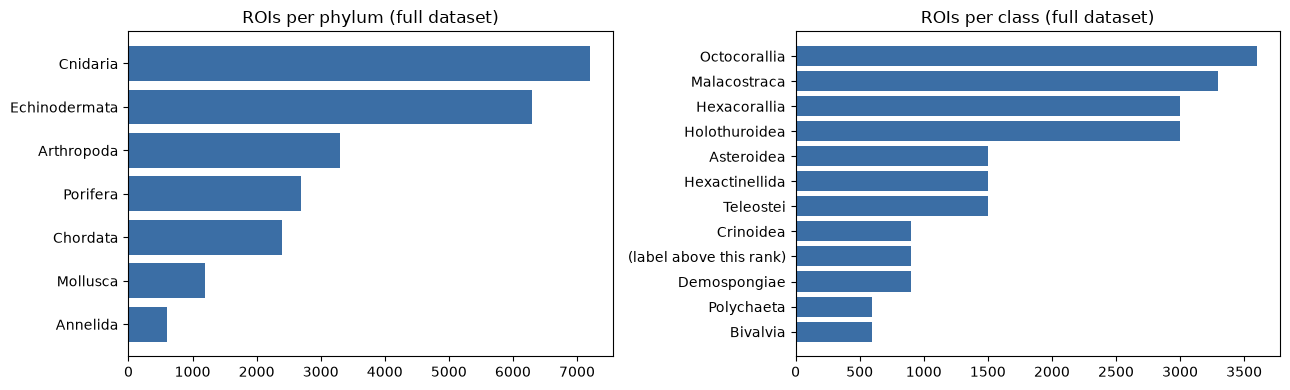

In [13]:
# Numbers for the FULL dataset from the verified reference run (no download needed)
ref = json.load(open("reference_output/summary.json"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a_, rk in zip(ax, ["phylum", "class"]):
    g = pd.Series(ref["samples_per_group"][rk]).head(12)[::-1]
    a_.barh(g.index, g.values, color="#3b6ea5"); a_.set_title(f"ROIs per {rk} (full dataset)")
plt.tight_layout(); plt.show()

## 8. Full run and known issues
```bash
python prepare_fathomnet2025.py            # all 8,981 images, resumable
```
Expected: 23,698 crops, 1 failure (annotation 21685), 79/79 categories present. See `KNOWN_ISSUES.md` for every pitfall
found (bbox clipping, empty WoRMS ranks, duplicated boxes, tiny objects, …).